### NACA CAMBERED  AIRFOIL


Lagrang interpolation:
Upper Surface:
Maximum Error : 0.007030968781121533
RMS Error: 0.0009549570463079938
Lower Surface:
Maximum Error: 0.0067089365948100645
RMS Error : 0.0009107738555700411


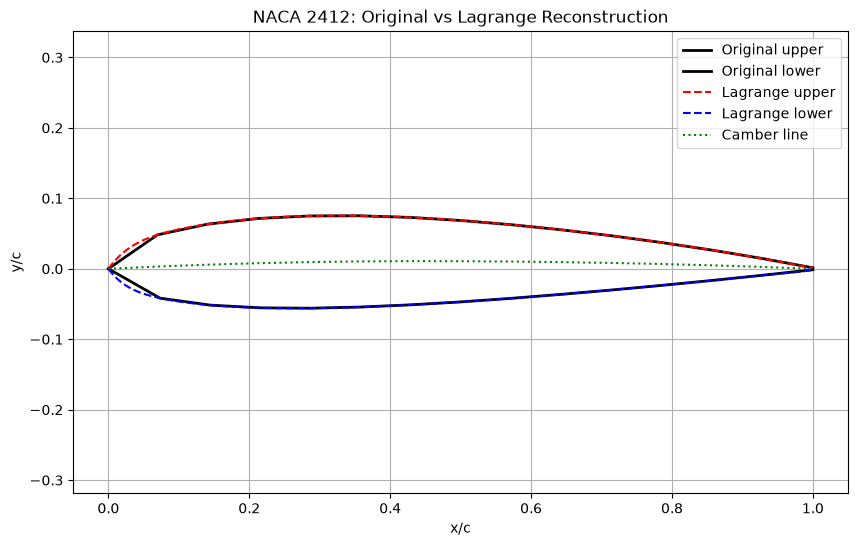

In [8]:
import numpy as np
import matplotlib.pyplot as plt

n = 15

x = np.linspace(0, 1, n)

rng = np.random.default_rng()

m = rng.uniform(0.01, 0.06)
p = rng.uniform(0.20, 0.60)
t = rng.uniform(0.08, 0.18)

yt = 5 * t * ( 0.2969 * np.sqrt(x)- 0.1260 * x- 0.3516 * x**2+ 0.2843 * x**3 - 0.1015 * x**4)

yc = np.zeros(n)
dyc_dx = np.zeros(n)

for i in range(len(x)):

    if x[i] <= p:

        yc[i] = (m / p**2) * (2 * p * x[i] - x[i]**2)
        dyc_dx[i] = (2 * m / p**2) * (p - x[i])

    else:

        yc[i] = (m / (1 - p)**2) * ((1 - 2 * p)+ 2 * p * x[i]- x[i]**2)
        dyc_dx[i] = (2 * m / (1 - p)**2) * ( p - x[i])

theta = np.arctan(dyc_dx)

xu = x - yt * np.sin(theta)
yu = yc + yt * np.cos(theta)

xl = x + yt * np.sin(theta)
yl = yc - yt * np.cos(theta)

def lagrng(x_data, y_data, n_points, x_value):

    result = 0.0

    for i in range(n_points):

        product = y_data[i]

        for j in range(n_points):

            if i != j:

                product = product * ( (x_value - x_data[j]) / (x_data[i] - x_data[j]))

        result = result + product

    return result

xx = np.linspace(0, 1, 200)

y_u_lagrng = np.zeros(len(xx))
y_l_lagrng = np.zeros(len(xx))

for k in range(len(xx)):

    y_u_lagrng[k] = lagrng(xu,yu,len(xu),xx[k])
    y_l_lagrng[k] = lagrng(xl,yl,len(xl),xx[k])

yt_true = 5 * t * (0.2969 * np.sqrt(xx)- 0.1260 * xx- 0.3516 * xx**2+ 0.2843 * xx**3- 0.1015 * xx**4)

yc_true = np.zeros(len(xx))
dyc_dx_true = np.zeros(len(xx))

for i in range(len(xx)):

    if xx[i] <= p:

        yc_true[i] = (m / p**2) * (2 * p * xx[i] - xx[i]**2)
        dyc_dx_true[i] = (2 * m / p**2) * (p - xx[i])

    else:

        yc_true[i] = (m / (1 - p)**2) * ( (1 - 2 * p) + 2 * p * xx[i]- xx[i]**2)
        dyc_dx_true[i] = (2 * m / (1 - p)**2) * (p - xx[i])


theta_true = np.arctan(dyc_dx_true)

xu_true = xx - yt_true * np.sin(theta_true)
yu_true = yc_true + yt_true * np.cos(theta_true)

xl_true = xx + yt_true * np.sin(theta_true)
yl_true = yc_true - yt_true * np.cos(theta_true)

error_upper = yu_true - y_u_lagrng
error_lower = yl_true - y_l_lagrng


max_error_upper = np.max(np.abs(error_upper))
max_error_lower = np.max(np.abs(error_lower))


rms_upper = np.sqrt(np.mean(error_upper**2))
rms_lower = np.sqrt(np.mean(error_lower**2))


print("Lagrang interpolation:")
print("Upper Surface:")
print("Maximum Error :", max_error_upper)
print("RMS Error:", rms_upper)

print("Lower Surface:")
print("Maximum Error:", max_error_lower)
print("RMS Error :", rms_lower)

plt.figure(figsize=(10, 6))

plt.plot(xu,yu,'k-',linewidth=2,label='Original upper')
plt.plot(xl,yl,'k-',linewidth=2,label='Original lower')

plt.plot(xx,y_u_lagrng,'r--',linewidth=1.5,label='Lagrange upper')

plt.plot(xx, y_l_lagrng,'b--',linewidth=1.5,label='Lagrange lower')

plt.plot(x,yc,'g:',linewidth=1.5,label='Camber line')
plt.xlabel("x/c")
plt.ylabel("y/c")

plt.title("NACA 2412: Original vs Lagrange Reconstruction")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

# Cambered NACA Airfoil Reconstruction Using Lagrange Interpolation

## 1. Problem Statement

The objective of this work is to reconstruct a smooth cambered NACA four-digit airfoil from a limited number of geometry points using Lagrange polynomial interpolation. The maximum camber, location of maximum camber, and maximum thickness-to-chord ratio are selected randomly within specified ranges using a NumPy random number generator. The NACA airfoil geometry is first generated using the standard thickness and camber-line equations. A specified number of points is then selected from the airfoil surface and used as the interpolation data. The reconstructed upper and lower surfaces are compared with the original airfoil, and the maximum and root mean square (RMS) errors are calculated. The effect of the spacing of the data points on the reconstruction accuracy is also investigated.

## 2. Approach and Numerical Method

The chord length is normalized to unity, such that \(0\leq x\leq1\). The maximum camber \(m\), location of maximum camber \(p\), and thickness-to-chord ratio \(t\) are randomly selected within the ranges \(0.01\leq m\leq0.06\), \(0.20\leq p\leq0.60\), and \(0.08\leq t\leq0.18\), respectively. The thickness distribution of the NACA four-digit airfoil is calculated using

$$
y_t=5t\left(0.2969\sqrt{x}-0.1260x-0.3516x^2+0.2843x^3-0.1015x^4\right).
$$

The camber line is defined separately before and after the location of maximum camber. For \(0\leq x\leq p\),

$$
y_c=\frac{m}{p^2}(2px-x^2),
$$

while for \(p<x\leq1\),

$$
y_c=\frac{m}{(1-p)^2}\left[(1-2p)+2px-x^2\right].
$$

The corresponding camber-line slope is obtained from

$$
\frac{dy_c}{dx}=
\frac{2m}{p^2}(p-x)
$$

for the forward section and

$$
\frac{dy_c}{dx}=
\frac{2m}{(1-p)^2}(p-x)
$$

for the rear section. The local inclination of the camber line is then given by

$$
\theta=\tan^{-1}\left(\frac{dy_c}{dx}\right).
$$

Using this angle, the coordinates of the upper and lower surfaces are calculated as

$$
x_u=x-y_t\sin\theta,\qquad
y_u=y_c+y_t\cos\theta
$$

and

$$
x_l=x+y_t\sin\theta,\qquad
y_l=y_c-y_t\cos\theta.
$$

These equations provide the original airfoil geometry against which the interpolated geometry is compared.

## 3. Numerical Algorithm

The numerical method begins by generating \(N\) points between zero and one and evaluating the NACA thickness distribution and camber-line equations at these points. The upper and lower surface coordinates are then obtained using the local camber-line angle. These \(N\) surface points are used as the interpolation data.

The reconstruction is performed using the Lagrange interpolation polynomial,

$$
P(x)=\sum_{i=0}^{N-1}y_i
\prod_{\substack{j=0\\j\neq i}}^{N-1}
\frac{x-x_j}{x_i-x_j}.
$$

The same interpolation procedure is applied independently to the upper and lower airfoil surfaces. The resulting polynomial is evaluated at 200 closely spaced chordwise locations to obtain a smooth reconstructed surface. The true airfoil is also evaluated at these same locations so that we can make a direct comparison between the true and reconstructed airfoils.

The interpolation error at each location is calculated from the difference between the true and reconstructed coordinates. For the upper surface,

$$
e_u=y_{u,\mathrm{true}}-y_{u,\mathrm{Lagrange}},
$$

and for the lower surface,

$$
e_l=y_{l,\mathrm{true}}-y_{l,\mathrm{Lagrange}}.
$$

while the RMS error is calculated using

$$
E_{\mathrm{RMS}}
=
\sqrt{\frac{1}{N}\sum_{i=1}^{N}e_i^2}.
$$

These two quantities provide measures of the worst local deviation and the overall reconstruction accuracy, respectively.

## 4. Results and Discussion

The original airfoil geometry and the Lagrange reconstructed geometry are plotted together to get the interpolation. For the selected number of data points, the reconstructed surface follows the original NACA airfoil closely when the interpolation points are distributed. The maximum error indicates the location at which the reconstructed surface deviates most from the original geometry, whereas the RMS error represents the average magnitude of the deviation over the complete surface.

The accuracy of the reconstruction is strongly dependent on the number and distribution of the interpolation points. The present calculation uses uniformly spaced points generated along the chord.

Increasing the number of points will provide a better representation of the airfoil,it will keep on smoothening and an accurate and smooth curve will be obtained at the end.
                        
## 5. Summary and Conclusion

A cambered NACA airfoil was generated using randomly selected camber, camber-location, and thickness parameters. The standard NACA thickness distribution and camber-line equations were used to obtain the upper and lower surface coordinates. These coordinates were then reconstructed using Lagrange polynomial interpolation and compared with the original airfoil geometry.

The reconstruction accuracy was quantified using maximum and RMS errors for both the upper and lower surfaces. The study demonstrates that interpolation accuracy depends not only on the number of available geometry points but also on their spatial distribution. Uniform spacing provides a basic reconstruction, while an appropriate non-uniform distribution such as cosine spacing can provide improved resolution near regions of high curvature. Hence, careful selection of the number and spacing of interpolation points is important for obtaining an accurate and smooth numerical reconstruction of an airfoil.

## 6. References
Used wikipedia for all the equations of Cambered airfoil and the variables , apart from this got some basic idea from youtube for calculating error and rms value .
https://www.youtube.com/watch?v=5MvyuMcqpFg
